<a href="https://colab.research.google.com/github/renatofb98/Data_science_projects/blob/main/Proje%C3%A7%C3%A3o%20receitas%20x%20despesas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ==========================================================
# CERQUILHO/SP — SITUAÇÃO FINANCEIRA
# Fonte: API oficial SICONFI / Tesouro Nacional
# RREO - Anexo 01 - Balanço Orçamentário
# Período: 2017 a 2026
#
# Preserva os registros originais retornados pela API.
# Não faz projeções nem preenche valores ausentes.
# ==========================================================

!pip -q install requests pandas openpyxl

import requests
import pandas as pd
import time
import re
import unicodedata
from decimal import Decimal
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.chart import LineChart, BarChart, Reference
from google.colab import files

IBGE = 3511508
ANOS = range(2017, 2027)
ARQUIVO = "Cerquilho_Situacao_Financeira_SICONFI.xlsx"

BASES_API = [
    "https://apidatalake.tesouro.gov.br/ords/siconfi/tt",
    "https://apidatalake.tesouro.gov.br/ords/cdwhprd/siconfi/tt"
]

sessao = requests.Session()
ultimo_acesso = 0

# ----------------------------------------------------------
# 1. FUNÇÕES AUXILIARES
# ----------------------------------------------------------

def normalizar(valor):
    texto = str(valor or "")
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        c for c in texto if not unicodedata.combining(c)
    )
    return re.sub(r"\s+", " ", texto.upper()).strip()


def para_numero(valor):
    if valor is None or str(valor).strip() == "":
        return None

    if isinstance(valor, (int, float)):
        return float(valor)

    texto = str(valor).strip().replace("R$", "").replace(" ", "")

    if "," in texto:
        texto = texto.replace(".", "").replace(",", ".")

    try:
        return float(Decimal(texto))
    except Exception:
        return None


def consultar_api(parametros):
    global ultimo_acesso

    ultimo_erro = None

    for base in BASES_API:
        url = base + "/rreo"

        for tentativa in range(3):
            intervalo = time.monotonic() - ultimo_acesso
            if intervalo < 1.2:
                time.sleep(1.2 - intervalo)

            ultimo_acesso = time.monotonic()

            try:
                resposta = sessao.get(
                    url,
                    params=parametros,
                    timeout=60
                )
                resposta.raise_for_status()
                dados = resposta.json()

                itens = list(dados.get("items", []))

                # Paginação oficial ORDS
                pagina = dados

                while pagina.get("hasMore", False):
                    links = pagina.get("links", [])
                    proxima = next(
                        (
                            x.get("href")
                            for x in links
                            if x.get("rel") == "next"
                        ),
                        None
                    )

                    if not proxima:
                        raise RuntimeError(
                            "Paginação incompleta: próximo link ausente."
                        )

                    intervalo = time.monotonic() - ultimo_acesso
                    if intervalo < 1.2:
                        time.sleep(1.2 - intervalo)

                    ultimo_acesso = time.monotonic()

                    r = sessao.get(proxima, timeout=60)
                    r.raise_for_status()
                    pagina = r.json()
                    itens.extend(pagina.get("items", []))

                return itens

            except (requests.RequestException, ValueError) as erro:
                ultimo_erro = str(erro)
                time.sleep(2 * (tentativa + 1))

    raise RuntimeError(
        "Falha ao consultar API: " + str(ultimo_erro)
    )


# ----------------------------------------------------------
# 2. BAIXAR DADOS DO RREO
# ----------------------------------------------------------

originais = []
logs = []

print("Consultando RREO de Cerquilho...\n")

for ano in ANOS:

    # 2026 ainda está em andamento.
    # A busca começa no 5º bimestre.
    primeiro_periodo = 5 if ano == 2026 else 6

    registros_ano = []
    periodo_encontrado = None
    erros_ano = []

    for periodo in range(primeiro_periodo, 0, -1):

        parametros = {
            "an_exercicio": ano,
            "nr_periodo": periodo,
            "co_tipo_demonstrativo": "RREO",
            "no_anexo": "RREO-Anexo 01",
            "id_ente": IBGE
        }

        try:
            itens = consultar_api(parametros)

            if itens:
                registros_ano = itens
                periodo_encontrado = periodo
                break

        except Exception as erro:
            erros_ano.append(
                f"Bimestre {periodo}: {erro}"
            )

    if registros_ano:
        for registro in registros_ano:
            linha = dict(registro)
            linha["ano_consulta"] = ano
            linha["bimestre_consulta"] = periodo_encontrado
            originais.append(linha)

        status = "DADOS OBTIDOS"
    else:
        status = "NÃO ENCONTRADO"

    logs.append({
        "ano": ano,
        "bimestre": periodo_encontrado,
        "registros": len(registros_ano),
        "status": status,
        "erros": " | ".join(erros_ano)
    })

    print(
        f"{ano}: {status} | "
        f"Bimestre: {periodo_encontrado} | "
        f"Registros: {len(registros_ano)}"
    )

if not originais:
    raise RuntimeError(
        "Nenhum dado foi retornado. "
        "Verifique a conexão e a disponibilidade da API."
    )

df = pd.DataFrame(originais)

campos = ["conta", "coluna", "valor"]

for campo in campos:
    if campo not in df.columns:
        raise RuntimeError(
            f"Campo '{campo}' não encontrado na API. "
            f"Campos disponíveis: {list(df.columns)}"
        )

# Preservar a informação original
df["conta_normalizada"] = df["conta"].apply(normalizar)
df["coluna_normalizada"] = df["coluna"].apply(normalizar)
df["valor_numerico"] = df["valor"].apply(para_numero)


# ----------------------------------------------------------
# 3. IDENTIFICAR RECEITAS E DESPESAS
# ----------------------------------------------------------
# Seleciona APENAS as contas sintéticas:
# RECEITAS (EXCETO INTRA-ORÇAMENTÁRIAS)
# DESPESAS (EXCETO INTRA-ORÇAMENTÁRIAS)
#
# Não soma contas analíticas nem outros totais.
# ----------------------------------------------------------

def identificar_registros(dados, tipo):

    if tipo == "receita":

        filtro_conta = dados["conta_normalizada"].str.match(
            r"^RECEITAS\s*\(EXCETO INTRA"
        )

        filtro_coluna = (
            dados["coluna_normalizada"].str.contains(
                "ATE O BIMESTRE", regex=False
            )
            &
            (
                dados["coluna_normalizada"].str.contains(
                    "RECEITAS REALIZADAS", regex=False
                )
                |
                dados["coluna_normalizada"].str.match(
                    r"^ATE O BIMESTRE\s*\(C\)"
                )
            )
        )

    else:

        filtro_conta = dados["conta_normalizada"].str.match(
            r"^DESPESAS\s*\(EXCETO INTRA"
        )

        filtro_coluna = (
            dados["coluna_normalizada"].str.contains(
                "DESPESAS EMPENHADAS", regex=False
            )
            &
            dados["coluna_normalizada"].str.contains(
                "ATE O BIMESTRE", regex=False
            )
        )

    return dados.loc[filtro_conta & filtro_coluna].copy()


resultados = []
conferencia = []

for item in logs:

    ano = item["ano"]
    periodo = item["bimestre"]

    if periodo is None:
        resultados.append({
            "Ano": ano,
            "Bimestre": None,
            "Situação": "SEM DADOS",
            "Receita (R$)": None,
            "Despesa (R$)": None
        })
        continue

    dados_ano = df[
        (df["ano_consulta"] == ano) &
        (df["bimestre_consulta"] == periodo)
    ]

    receita_df = identificar_registros(dados_ano, "receita")
    despesa_df = identificar_registros(dados_ano, "despesa")

    for tipo, selecionados in [
        ("Receita", receita_df),
        ("Despesa", despesa_df)
    ]:
        for _, linha in selecionados.iterrows():
            conferencia.append({
                "Ano": ano,
                "Bimestre": periodo,
                "Tipo": tipo,
                "Código da conta": linha.get("cod_conta"),
                "Conta": linha["conta"],
                "Coluna": linha["coluna"],
                "Valor informado": linha["valor"],
                "Valor numérico": linha["valor_numerico"]
            })

    # Não escolher arbitrariamente entre duplicidades.
    def valor_unico(selecionados):
        if len(selecionados) != 1:
            return None
        return selecionados.iloc[0]["valor_numerico"]

    receita = valor_unico(receita_df)
    despesa = valor_unico(despesa_df)

    status = (
        "OK"
        if receita is not None and despesa is not None
        else "REVISAR CONTAS/COLUNAS"
    )

    resultados.append({
        "Ano": ano,
        "Bimestre": periodo,
        "Situação": status,
        "Receita (R$)": receita,
        "Despesa (R$)": despesa
    })


# ----------------------------------------------------------
# 4. CRIAR PLANILHA COM FÓRMULAS
# ----------------------------------------------------------

resumo = pd.DataFrame(resultados)

resumo["Resultado (R$)"] = None
resumo["Receita (R$ mi)"] = None
resumo["Despesa (R$ mi)"] = None
resumo["Resultado (R$ mi)"] = None
resumo["Crescimento receita"] = None
resumo["Crescimento despesa"] = None

metodologia = pd.DataFrame([
    ["Município", "Cerquilho/SP"],
    ["Código IBGE", IBGE],
    ["Fonte", "SICONFI - RREO - Anexo 01"],
    ["Receitas", "Receitas realizadas até o bimestre, exceto intraorçamentárias"],
    ["Despesas", "Despesas empenhadas até o bimestre, exceto intraorçamentárias"],
    ["Resultado", "Receita realizada menos despesa empenhada"],
    ["Exercícios", "2017 a 2026"],
    ["2026", "Parcial; último bimestre disponível até o 5º"],
    ["Projeções", "Nenhuma"],
    ["Valores ausentes", "Mantidos vazios para conferência"],
    ["Crescimento anual", "Calculado somente para exercícios completos e válidos"],
    ["Observação", "Não somar contas sintéticas e analíticas do RREO"],
    ["Documentação", "https://apidatalake.tesouro.gov.br/docs/siconfi/"]
], columns=["Critério", "Descrição"])

with pd.ExcelWriter(ARQUIVO, engine="openpyxl") as writer:
    resumo.to_excel(writer, sheet_name="SLIDE", index=False)
    df.to_excel(writer, sheet_name="DADOS_ORIGINAIS", index=False)
    pd.DataFrame(conferencia).to_excel(
        writer, sheet_name="CONFERENCIA", index=False
    )
    pd.DataFrame(logs).to_excel(
        writer, sheet_name="LOG_CONSULTAS", index=False
    )
    metodologia.to_excel(
        writer, sheet_name="METODOLOGIA", index=False
    )


# ----------------------------------------------------------
# 5. FÓRMULAS, FORMATAÇÃO E GRÁFICOS
# ----------------------------------------------------------

wb = load_workbook(ARQUIVO)
ws = wb["SLIDE"]

formato_reais = '"R$" #,##0.00;[Red]-"R$" #,##0.00'
formato_milhoes = '0.00'
formato_pct = '0.00%'

for linha in range(2, ws.max_row + 1):

    ano = ws.cell(linha, 1).value
    status = ws.cell(linha, 3).value

    if status != "OK":
        continue

    # Resultado orçamentário
    ws[f"F{linha}"] = f"=D{linha}-E{linha}"

    # Valores em milhões para os gráficos
    ws[f"G{linha}"] = f"=D{linha}/1000000"
    ws[f"H{linha}"] = f"=E{linha}/1000000"
    ws[f"I{linha}"] = f"=F{linha}/1000000"

    for coluna in ["D", "E", "F"]:
        ws[f"{coluna}{linha}"].number_format = formato_reais

    for coluna in ["G", "H", "I"]:
        ws[f"{coluna}{linha}"].number_format = formato_milhoes

    # Crescimento anual: apenas exercícios completos
    if linha > 2 and ano <= 2025:
        anterior = linha - 1

        if (
            ws[f"C{anterior}"].value == "OK"
            and ws[f"B{linha}"].value == 6
            and ws[f"B{anterior}"].value == 6
        ):
            ws[f"J{linha}"] = (
                f'=IFERROR(D{linha}/D{anterior}-1,"")'
            )
            ws[f"K{linha}"] = (
                f'=IFERROR(E{linha}/E{anterior}-1,"")'
            )
            ws[f"J{linha}"].number_format = formato_pct
            ws[f"K{linha}"].number_format = formato_pct


# Indicadores de crescimento médio anual composto
ws["M2"] = "INDICADORES 2017–2025"
ws["M4"] = "CAGR Receita"
ws["M5"] = "CAGR Despesa"

# 2017: linha 2; 2025: linha 10
if all(
    ws[f"C{r}"].value == "OK" and ws[f"B{r}"].value == 6
    for r in [2, 10]
):
    ws["N4"] = "=(D10/D2)^(1/(A10-A2))-1"
    ws["N5"] = "=(E10/E2)^(1/(A10-A2))-1"
    ws["N4"].number_format = formato_pct
    ws["N5"].number_format = formato_pct
else:
    ws["N4"] = "Conferir dados"
    ws["N5"] = "Conferir dados"


# Gráfico de receitas e despesas: somente 2017–2025
grafico1 = LineChart()
grafico1.title = "Receitas e despesas realizadas (R$ mi)"
grafico1.y_axis.title = "R$ milhões"
grafico1.x_axis.title = "Ano"
grafico1.style = 13
grafico1.width = 18
grafico1.height = 9

for coluna in [7, 8]:
    valores = Reference(
        ws,
        min_col=coluna,
        min_row=1,
        max_row=10
    )
    grafico1.add_data(valores, titles_from_data=True)

categorias = Reference(
    ws, min_col=1, min_row=2, max_row=10
)
grafico1.set_categories(categorias)
ws.add_chart(grafico1, "M8")


# Gráfico de resultado orçamentário
grafico2 = BarChart()
grafico2.type = "col"
grafico2.style = 10
grafico2.title = "Resultado orçamentário (R$ mi)"
grafico2.y_axis.title = "R$ milhões"
grafico2.width = 18
grafico2.height = 9

valores = Reference(
    ws, min_col=9, min_row=1, max_row=10
)
grafico2.add_data(valores, titles_from_data=True)
grafico2.set_categories(categorias)
ws.add_chart(grafico2, "M27")


# Estilo das abas
for aba in wb.worksheets:
    aba.freeze_panes = "A2"
    aba.auto_filter.ref = aba.dimensions

    for celula in aba[1]:
        celula.fill = PatternFill(
            "solid", fgColor="10374A"
        )
        celula.font = Font(
            bold=True, color="FFFFFF"
        )
        celula.alignment = Alignment(
            vertical="center"
        )

    aba.row_dimensions[1].height = 30

    for coluna in aba.columns:
        letra = coluna[0].column_letter

        # Limite de largura para não deformar a planilha
        maior = max(
            len(str(c.value or ""))
            for c in list(coluna)[:100]
        )

        aba.column_dimensions[letra].width = min(
            max(maior + 2, 14), 42
        )

# Larguras específicas
for col in ["D", "E", "F", "G", "H", "I"]:
    ws.column_dimensions[col].width = 21

ws.column_dimensions["C"].width = 27
ws.column_dimensions["M"].width = 24
ws.column_dimensions["N"].width = 20

# Solicitar recálculo das fórmulas ao abrir no Excel
try:
    wb.calculation.fullCalcOnLoad = True
    wb.calculation.forceFullCalc = True
    wb.calculation.calcMode = "auto"
except Exception:
    pass

wb.save(ARQUIVO)

# ----------------------------------------------------------
# 6. RESULTADO DA EXTRAÇÃO
# ----------------------------------------------------------

print("\n" + "=" * 55)
print("RESUMO DA EXTRAÇÃO")
print("=" * 55)

print(resumo[
    ["Ano", "Bimestre", "Situação",
     "Receita (R$)", "Despesa (R$)"]
].to_string(index=False))

pendencias = resumo[resumo["Situação"] != "OK"]

if not pendencias.empty:
    print("\nATENÇÃO: há anos que precisam de conferência.")
    print(pendencias[["Ano", "Situação"]].to_string(index=False))
    print("Consulte as abas CONFERENCIA e DADOS_ORIGINAIS.")

print("\nArquivo criado:", ARQUIVO)

files.download(ARQUIVO)


Consultando RREO de Cerquilho...

2017: DADOS OBTIDOS | Bimestre: 6 | Registros: 376
2018: DADOS OBTIDOS | Bimestre: 6 | Registros: 404
2019: DADOS OBTIDOS | Bimestre: 6 | Registros: 402
2020: DADOS OBTIDOS | Bimestre: 6 | Registros: 410
2021: DADOS OBTIDOS | Bimestre: 6 | Registros: 398
2022: DADOS OBTIDOS | Bimestre: 6 | Registros: 404
2023: DADOS OBTIDOS | Bimestre: 6 | Registros: 407
2024: DADOS OBTIDOS | Bimestre: 6 | Registros: 409
2025: DADOS OBTIDOS | Bimestre: 6 | Registros: 407
2026: DADOS OBTIDOS | Bimestre: 4 | Registros: 376

RESUMO DA EXTRAÇÃO
 Ano  Bimestre Situação  Receita (R$)  Despesa (R$)
2017         6       OK  146238965.53  131479058.73
2018         6       OK  155945212.13  148479501.40
2019         6       OK  172179605.15  157658489.18
2020         6       OK  175537228.01  171510516.16
2021         6       OK  194465726.46  180521159.22
2022         6       OK  244562769.71  228815914.16
2023         6       OK  250440348.21  256727985.93
2024         6      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Consultando dados bimestrais do SICONFI...
Consultando 2017, bimestre 1...
Consultando 2017, bimestre 2...
Consultando 2017, bimestre 3...
Consultando 2017, bimestre 4...
Consultando 2017, bimestre 5...
Consultando 2017, bimestre 6...
Consultando 2018, bimestre 1...
Consultando 2018, bimestre 2...
Consultando 2018, bimestre 3...
Consultando 2018, bimestre 4...
Consultando 2018, bimestre 5...
Consultando 2018, bimestre 6...
Consultando 2019, bimestre 1...
Consultando 2019, bimestre 2...
Consultando 2019, bimestre 3...
Consultando 2019, bimestre 4...
Consultando 2019, bimestre 5...
Consultando 2019, bimestre 6...
Consultando 2020, bimestre 1...
Consultando 2020, bimestre 2...
Consultando 2020, bimestre 3...
Consultando 2020, bimestre 4...
Consultando 2020, bimestre 5...
Consultando 2020, bimestre 6...
Consultando 2021, bimestre 1...
Consultando 2021, bimestre 2...
Consultando 2021, bimestre 3...
Consultando 2021, bimestre 4...
Consultando 2021, bimestre 5...
Consultando 2021, bimestre 6.

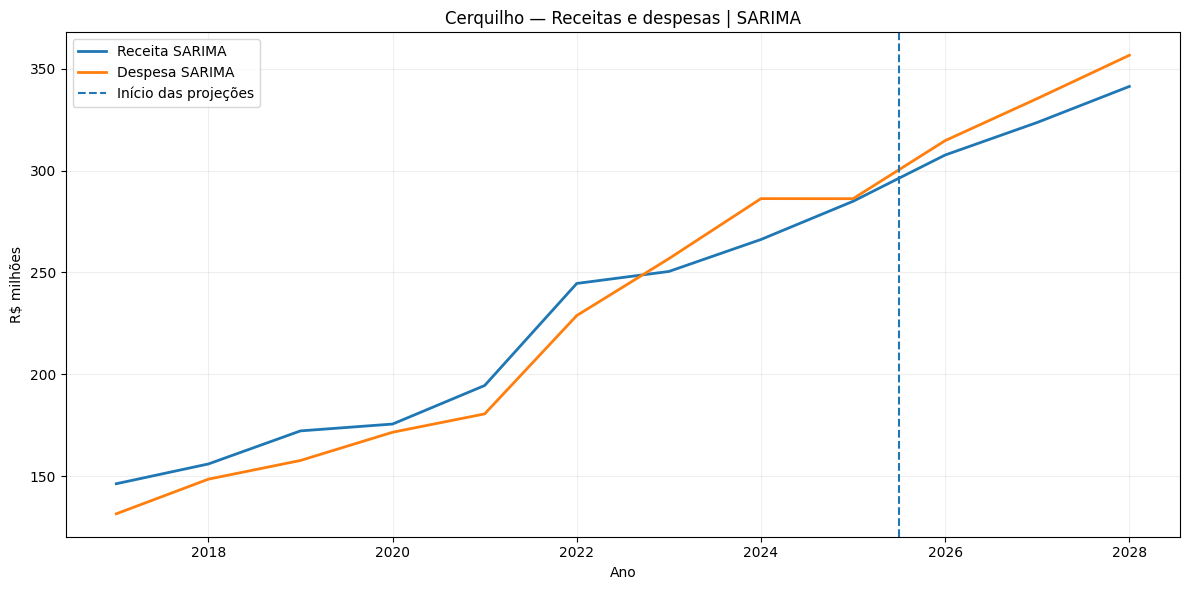

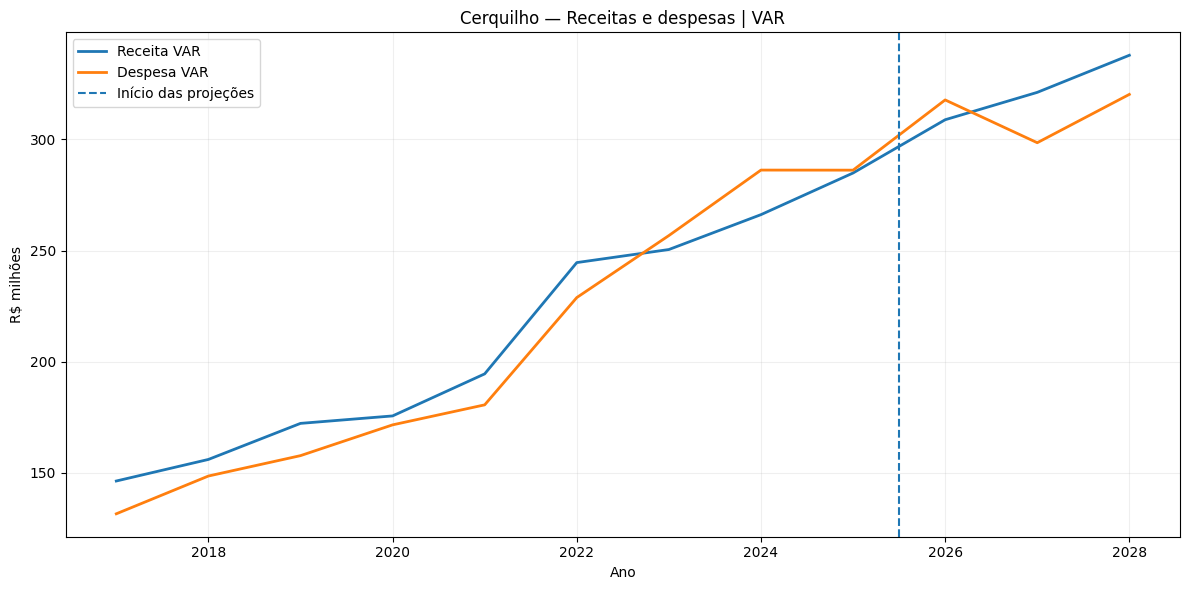


RESUMO ANUAL (R$ MILHÕES)
 Ano  Receita SARIMA  Despesa SARIMA  Receita VAR  Despesa VAR  Resultado SARIMA  Resultado VAR             Situação
2017          146.24          131.48       146.24       131.48             14.76          14.76            REALIZADO
2018          155.95          148.48       155.95       148.48              7.47           7.47            REALIZADO
2019          172.18          157.66       172.18       157.66             14.52          14.52            REALIZADO
2020          175.54          171.51       175.54       171.51              4.03           4.03            REALIZADO
2021          194.47          180.52       194.47       180.52             13.94          13.94            REALIZADO
2022          244.56          228.82       244.56       228.82             15.75          15.75            REALIZADO
2023          250.44          256.73       250.44       256.73             -6.29          -6.29            REALIZADO
2024          266.14          286.20 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CERQUILHO — PROJEÇÕES SARIMA E VAR
# SICONFI / RREO ANEXO 01
# Histórico: 2017 até último bimestre disponível de 2026
# Previsão: até 2028
# ============================================================

!pip -q install requests pandas numpy statsmodels openpyxl matplotlib

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import unicodedata
import re
import time
import warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from google.colab import files

warnings.filterwarnings("ignore")

# ---------------------- CONFIGURAÇÕES ----------------------

IBGE = 3511508
ANO_INICIAL = 2017
ANO_FINAL_PROJECAO = 2028

URL_API = (
    "https://apidatalake.tesouro.gov.br"
    "/ords/cdwhprd/siconfi/tt/rreo"
)

ARQUIVO = "CERQUILHO_SARIMA_VAR.xlsx"

sessao = requests.Session()
ultima_requisicao = 0


# ---------------------- API SICONFI ------------------------

def requisicao(url, parametros=None):
    global ultima_requisicao

    for tentativa in range(4):
        intervalo = time.monotonic() - ultima_requisicao
        if intervalo < 1.2:
            time.sleep(1.2 - intervalo)

        ultima_requisicao = time.monotonic()

        try:
            r = sessao.get(
                url,
                params=parametros,
                timeout=90
            )
            r.raise_for_status()
            return r.json()

        except Exception:
            if tentativa == 3:
                raise
            time.sleep(2 * (tentativa + 1))


def baixar_rreo(ano, bimestre):
    parametros = {
        "an_exercicio": ano,
        "nr_periodo": bimestre,
        "co_tipo_demonstrativo": "RREO",
        "no_anexo": "RREO-Anexo 01",
        "id_ente": IBGE
    }

    dados = requisicao(URL_API, parametros)
    itens = list(dados.get("items", []))

    while dados.get("hasMore", False):
        proximo = next(
            (x["href"] for x in dados.get("links", [])
             if x.get("rel") == "next"),
            None
        )

        if not proximo:
            raise RuntimeError("Paginação incompleta.")

        dados = requisicao(proximo)
        itens.extend(dados.get("items", []))

    return itens


def normalizar(texto):
    texto = unicodedata.normalize(
        "NFKD", str(texto or "")
    )
    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )
    return re.sub(r"\s+", " ", texto.upper()).strip()


def numero(valor):
    if pd.isna(valor):
        return np.nan

    if isinstance(valor, (int, float)):
        return float(valor)

    valor = str(valor).strip().replace(" ", "")

    if "," in valor:
        valor = valor.replace(".", "").replace(",", ".")

    return float(valor)


def localizar_valor(df, tipo):
    contas = df["conta"].map(normalizar)
    colunas = df["coluna"].map(normalizar)

    if tipo == "receita":
        filtro = (
            contas.str.match(r"^RECEITAS\s*\(EXCETO INTRA")
            &
            colunas.str.match(
                r"^ATE O BIMESTRE\s*\(C\)$"
            )
        )

    else:
        filtro = (
            contas.str.match(r"^DESPESAS\s*\(EXCETO INTRA")
            &
            colunas.str.contains(
                "DESPESAS EMPENHADAS ATE O BIMESTRE",
                regex=False
            )
        )

    encontrados = df.loc[filtro]

    if len(encontrados) != 1:
        raise ValueError(
            f"{tipo}: esperado 1 registro, "
            f"encontrados {len(encontrados)}. "
            "Verifique a aba DADOS_ORIGINAIS."
        )

    return numero(encontrados.iloc[0]["valor"])


# ---------------------- EXTRAÇÃO ---------------------------

print("Consultando dados bimestrais do SICONFI...")

dados_originais = []
acumulados = []
log = []

for ano in range(ANO_INICIAL, 2027):

    for bimestre in range(1, 7):

        # Não consultar o 6º bimestre de 2026,
        # que ainda não terminou.
        if ano == 2026 and bimestre == 6:
            continue

        print(f"Consultando {ano}, bimestre {bimestre}...")

        try:
            registros = baixar_rreo(ano, bimestre)

            if not registros:
                log.append({
                    "Ano": ano,
                    "Bimestre": bimestre,
                    "Situação": "SEM DADOS"
                })
                continue

            df_periodo = pd.DataFrame(registros)

            for registro in registros:
                dados_originais.append({
                    "Ano consulta": ano,
                    "Bimestre consulta": bimestre,
                    **registro
                })

            receita = localizar_valor(df_periodo, "receita")
            despesa = localizar_valor(df_periodo, "despesa")

            acumulados.append({
                "Ano": ano,
                "Bimestre": bimestre,
                "Receita acumulada": receita,
                "Despesa acumulada": despesa
            })

            log.append({
                "Ano": ano,
                "Bimestre": bimestre,
                "Situação": "OK"
            })

        except Exception as erro:
            print("  Aviso:", erro)
            log.append({
                "Ano": ano,
                "Bimestre": bimestre,
                "Situação": str(erro)
            })

historico = pd.DataFrame(acumulados)

if historico.empty:
    raise RuntimeError("Nenhum período válido encontrado.")

historico = historico.sort_values(
    ["Ano", "Bimestre"]
).reset_index(drop=True)

# Exigir que a série histórica seja contínua.
esperado = [
    (ano, b)
    for ano in range(2017, 2026)
    for b in range(1, 7)
]

encontrados = set(
    zip(historico["Ano"], historico["Bimestre"])
)

faltantes = [x for x in esperado if x not in encontrados]

if faltantes:
    raise RuntimeError(
        "Há bimestres ausentes entre 2017 e 2025: "
        f"{faltantes}. Não é seguro ajustar os modelos "
        "sem tratar essas lacunas."
    )

# Usar apenas os bimestres consecutivos disponíveis.
# Isso impede que uma lacuna em 2026 seja ignorada.
sequencia = []
for ano in range(2017, 2027):
    for bimestre in range(1, 7):
        if ano == 2026 and bimestre == 6:
            break
        if (ano, bimestre) in encontrados:
            sequencia.append((ano, bimestre))
        else:
            if ano == 2026:
                break

ultimo = sequencia[-1]
limite = ultimo[0] * 6 + ultimo[1]

historico = historico[
    historico["Ano"] * 6 + historico["Bimestre"] <= limite
].copy()

# ---------------------- FLUXOS BIMESTRAIS ------------------

historico["Receita"] = historico.groupby("Ano")[
    "Receita acumulada"
].diff()

historico["Despesa"] = historico.groupby("Ano")[
    "Despesa acumulada"
].diff()

primeiro = historico["Bimestre"] == 1

historico.loc[primeiro, "Receita"] = historico.loc[
    primeiro, "Receita acumulada"
]
historico.loc[primeiro, "Despesa"] = historico.loc[
    primeiro, "Despesa acumulada"
]

# Em R$ milhões para facilitar os modelos e os gráficos.
historico["Receita"] /= 1_000_000
historico["Despesa"] /= 1_000_000

historico["Resultado"] = (
    historico["Receita"] - historico["Despesa"]
)

historico["Periodo"] = (
    historico["Ano"].astype(str)
    + "-B"
    + historico["Bimestre"].astype(str)
)


# Criar índice temporal reconhecido pelo statsmodels
historico["Data"] = pd.to_datetime(
    dict(
        year=historico["Ano"],
        month=historico["Bimestre"] * 2,
        day=1
    )
)

series = historico.set_index("Data")[
    ["Receita", "Despesa"]
].astype(float)

# Frequência: um registro a cada dois meses
series = series.asfreq("2MS")

# Conferir se a conversão preservou as observações
if series.isna().any().any():
    raise ValueError(
        "Existem períodos ausentes após a conversão. "
        "Verifique a continuidade dos dados."
    )

print("Índice temporal corrigido.")
print(series.index[:5])
print("Frequência:", series.index.freq)


if not np.isfinite(series.to_numpy()).all():
    raise RuntimeError("Existem valores ausentes ou inválidos.")

print("\nÚltimo período:", ultimo)
print("Observações:", len(series))


# ---------------------- SARIMA -----------------------------

# Conjunto pequeno de configurações para evitar uma busca
# excessivamente complexa, considerando a série curta.
CANDIDATOS = [
    ((1,1,0), (1,0,0,6)),
    ((0,1,1), (0,1,1,6)),
    ((1,1,1), (0,1,1,6)),
    ((1,0,1), (1,0,0,6)),
    ((2,1,0), (0,1,1,6)),
    ((0,1,1), (1,0,0,6))
]



def ajustar_sarima(serie):

    # Garantir uma série numérica com índice temporal válido
    serie = pd.Series(
        serie.to_numpy(dtype=float),
        index=pd.date_range(
            start=serie.index[0],
            periods=len(serie),
            freq="2MS"
        )
    )

    melhor = None
    melhor_aic = np.inf
    configuracao = None

    for ordem, sazonal in CANDIDATOS:

        try:
            modelo = SARIMAX(
                serie,
                order=ordem,
                seasonal_order=sazonal,
                trend="n",
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            ajuste = modelo.fit(
                disp=False,
                maxiter=150
            )

            if (
                np.isfinite(ajuste.aic)
                and ajuste.aic < melhor_aic
            ):
                melhor = ajuste
                melhor_aic = ajuste.aic
                configuracao = (ordem, sazonal)

        except Exception as erro:
            print(
                f"Configuração {ordem}, {sazonal} "
                f"não funcionou: {erro}"
            )

    if melhor is None:
        raise RuntimeError(
            "Nenhum modelo SARIMA conseguiu convergir."
        )

    return melhor, configuracao



# ---------------------- VAR --------------------------------

# VAR sobre as diferenças dos fluxos bimestrais.
# As previsões são reconstruídas para o nível dos fluxos.

def ajustar_var(dados):
    diferencas = dados.diff().dropna()

    melhor = None
    melhor_aic = np.inf

    for defasagem in [1, 2]:
        try:
            ajuste = VAR(diferencas).fit(
                defasagem, trend="c"
            )

            if (
                np.isfinite(ajuste.aic)
                and ajuste.aic < melhor_aic
            ):
                melhor = ajuste
                melhor_aic = ajuste.aic

        except Exception:
            continue

    if melhor is None:
        raise RuntimeError("Não foi possível ajustar o VAR.")

    return melhor, diferencas


def prever_var(modelo, diferencas, ultima_linha, passos):
    previsao_diferencas = modelo.forecast(
        diferencas.values[-modelo.k_ar:],
        steps=passos
    )

    return (
        ultima_linha.values
        + np.cumsum(previsao_diferencas, axis=0)
    )


# ---------------------- VALIDAÇÃO HISTÓRICA ----------------

# Treinamento: 2017–2024
# Teste: seis bimestres de 2025

treino = series.iloc[:48]
teste = series.iloc[48:54]

print("\nValidando modelos contra 2025...")

previsoes_teste = {}
configuracoes = {}

for nome in ["Receita", "Despesa"]:
    modelo, config = ajustar_sarima(treino[nome])
    previsoes_teste[nome] = np.asarray(
        modelo.forecast(steps=6)
    )
    configuracoes[nome] = config

var_teste, diferencas_teste = ajustar_var(treino)

previsao_var_teste = prever_var(
    var_teste,
    diferencas_teste,
    treino.iloc[-1],
    6
)

def smape(real, previsto):
    real = np.asarray(real, dtype=float)
    previsto = np.asarray(previsto, dtype=float)

    denominador = np.abs(real) + np.abs(previsto)
    valido = denominador > 0

    if not valido.any():
        return 0.0

    return float(
        np.mean(
            200 * np.abs(real[valido] - previsto[valido])
            / denominador[valido]
        )
    )


validacao = []

for i, nome in enumerate(["Receita", "Despesa"]):

    real = teste[nome].to_numpy()
    sarima_prev = previsoes_teste[nome]
    var_prev = previsao_var_teste[:, i]

    for modelo_nome, previsao in [
        ("SARIMA", sarima_prev),
        ("VAR", var_prev)
    ]:
        validacao.append({
            "Modelo": modelo_nome,
            "Variável": nome,
            "MAE (R$ mi)": np.mean(
                np.abs(real - previsao)
            ),
            "sMAPE (%)": smape(real, previsao)
        })

validacao = pd.DataFrame(validacao)

print("\nDesempenho na validação de 2025:")
print(validacao.to_string(index=False))


# ---------------------- PREVISÃO FINAL ---------------------

# Reajusta os modelos usando todos os dados disponíveis.
# Prevê os bimestres seguintes até 2028.

ultimo_ano, ultimo_bimestre = ultimo

passos = (
    (ANO_FINAL_PROJECAO - ultimo_ano) * 6
    + (6 - ultimo_bimestre)
)

if passos <= 0:
    raise RuntimeError("Horizonte de previsão inválido.")

sarima_final = {}
previsoes_sarima = {}

for nome in ["Receita", "Despesa"]:
    modelo, config = ajustar_sarima(series[nome])
    sarima_final[nome] = config
    previsoes_sarima[nome] = np.asarray(
        modelo.forecast(steps=passos)
    )

var_final, dif_final = ajustar_var(series)

previsoes_var = prever_var(
    var_final,
    dif_final,
    series.iloc[-1],
    passos
)

anos_futuros = []
bimestres_futuros = []

ano = ultimo_ano
bimestre = ultimo_bimestre

for i in range(passos):
    bimestre += 1

    if bimestre > 6:
        bimestre = 1
        ano += 1

    anos_futuros.append(ano)
    bimestres_futuros.append(bimestre)

futuro = pd.DataFrame({
    "Ano": anos_futuros,
    "Bimestre": bimestres_futuros,
    "Periodo": [
        f"{a}-B{b}"
        for a, b in zip(
            anos_futuros, bimestres_futuros
        )
    ],
    "Receita SARIMA": previsoes_sarima["Receita"],
    "Despesa SARIMA": previsoes_sarima["Despesa"],
    "Receita VAR": previsoes_var[:, 0],
    "Despesa VAR": previsoes_var[:, 1]
})

futuro["Resultado SARIMA"] = (
    futuro["Receita SARIMA"]
    - futuro["Despesa SARIMA"]
)

futuro["Resultado VAR"] = (
    futuro["Receita VAR"]
    - futuro["Despesa VAR"]
)

# Preservar sinais negativos, se existirem,
# para não esconder previsões economicamente inadequadas.
futuro["Alerta"] = np.where(
    (futuro[
        ["Receita SARIMA", "Despesa SARIMA",
         "Receita VAR", "Despesa VAR"]
    ] < 0).any(axis=1),
    "PREVISÃO NEGATIVA — REVISAR",
    ""
)


# ---------------------- RESUMO ANUAL -----------------------

historico["Origem"] = "Realizado"
historico["Receita SARIMA"] = historico["Receita"]
historico["Despesa SARIMA"] = historico["Despesa"]
historico["Receita VAR"] = historico["Receita"]
historico["Despesa VAR"] = historico["Despesa"]

futuro["Origem"] = "Projetado"

base_anual = pd.concat([
    historico[
        ["Ano", "Bimestre", "Origem",
         "Receita SARIMA", "Despesa SARIMA",
         "Receita VAR", "Despesa VAR"]
    ],
    futuro[
        ["Ano", "Bimestre", "Origem",
         "Receita SARIMA", "Despesa SARIMA",
         "Receita VAR", "Despesa VAR"]
    ]
], ignore_index=True)

anual = base_anual.groupby("Ano", as_index=False)[
    ["Receita SARIMA", "Despesa SARIMA",
     "Receita VAR", "Despesa VAR"]
].sum()

anual["Resultado SARIMA"] = (
    anual["Receita SARIMA"]
    - anual["Despesa SARIMA"]
)
anual["Resultado VAR"] = (
    anual["Receita VAR"]
    - anual["Despesa VAR"]
)

anual["Situação"] = np.where(
    anual["Ano"] <= 2025,
    "REALIZADO",
    np.where(
        anual["Ano"] == 2026,
        "REALIZADO + PROJEÇÃO",
        "PROJEÇÃO"
    )
)

# Crescimento composto dos valores realizados, 2017–2025.
real_2017 = anual[anual["Ano"] == 2017].iloc[0]
real_2025 = anual[anual["Ano"] == 2025].iloc[0]

cagr_receita = (
    (real_2025["Receita SARIMA"]
     / real_2017["Receita SARIMA"])**(1/8) - 1
)
cagr_despesa = (
    (real_2025["Despesa SARIMA"]
     / real_2017["Despesa SARIMA"])**(1/8) - 1
)

indicadores = pd.DataFrame([
    ["Crescimento anual composto da receita 2017–2025",
     cagr_receita],
    ["Crescimento anual composto da despesa 2017–2025",
     cagr_despesa],
    ["SARIMA receita", str(sarima_final["Receita"])],
    ["SARIMA despesa", str(sarima_final["Despesa"])],
    ["VAR defasagens", var_final.k_ar],
    ["Último dado observado", f"{ultimo_ano}-B{ultimo_bimestre}"],
    ["Unidade dos valores projetados", "R$ milhões"]
], columns=["Indicador", "Valor"])


# ---------------------- EXPORTAR EXCEL ---------------------

with pd.ExcelWriter(ARQUIVO, engine="openpyxl") as writer:

    anual.to_excel(
        writer, "RESUMO_ANUAL", index=False
    )

    futuro.to_excel(
        writer, "PROJECOES_BIM", index=False
    )

    historico.to_excel(
        writer, "SERIE_HISTORICA", index=False
    )

    validacao.to_excel(
        writer, "VALIDACAO_2025", index=False
    )

    indicadores.to_excel(
        writer, "INDICADORES", index=False
    )

    pd.DataFrame(dados_originais).to_excel(
        writer, "DADOS_ORIGINAIS", index=False
    )

    pd.DataFrame(log).to_excel(
        writer, "LOG_API", index=False
    )


# ---------------------- GRÁFICOS ---------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    anual["Ano"], anual["Receita SARIMA"],
    label="Receita SARIMA", linewidth=2
)
plt.plot(
    anual["Ano"], anual["Despesa SARIMA"],
    label="Despesa SARIMA", linewidth=2
)

plt.axvline(
    2025.5, linestyle="--",
    label="Início das projeções"
)

plt.title("Cerquilho — Receitas e despesas | SARIMA")
plt.ylabel("R$ milhões")
plt.xlabel("Ano")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "CERQUILHO_SARIMA.png", dpi=180
)
plt.show()


plt.figure(figsize=(12, 6))

plt.plot(
    anual["Ano"], anual["Receita VAR"],
    label="Receita VAR", linewidth=2
)
plt.plot(
    anual["Ano"], anual["Despesa VAR"],
    label="Despesa VAR", linewidth=2
)

plt.axvline(
    2025.5, linestyle="--",
    label="Início das projeções"
)

plt.title("Cerquilho — Receitas e despesas | VAR")
plt.ylabel("R$ milhões")
plt.xlabel("Ano")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "CERQUILHO_VAR.png", dpi=180
)
plt.show()


print("\nRESUMO ANUAL (R$ MILHÕES)")
print(anual.round(2).to_string(index=False))

print("\nMODELOS SARIMA:")
print(sarima_final)

print("\nVAR: ", var_final.k_ar, "defasagem(ns)")

print("\nArquivos gerados:")
print(ARQUIVO)
print("CERQUILHO_SARIMA.png")
print("CERQUILHO_VAR.png")

files.download(ARQUIVO)


In [3]:

# ==========================================================
# CERQUILHO — REVISÃO DO VAR
# Comparação: VAR original x VAR anual x referência sazonal
# Usa a variável "series" criada no notebook anterior.
# ==========================================================

import numpy as np
import pandas as pd
from statsmodels.tsa.api import VAR
from google.colab import files

# Cópia dos dados para não alterar a série original
base = series[["Receita", "Despesa"]].copy()
base = base.reset_index(drop=True).astype(float)

if len(base) != 58:
    print("Atenção: foram encontradas", len(base),
          "observações, em vez das 58 do arquivo analisado.")

if (base <= 0).any().any():
    raise ValueError(
        "Há valores nulos ou negativos. "
        "A transformação logarítmica não pode ser aplicada."
    )


# ----------------------------------------------------------
# 1. VAR ORIGINAL
# Diferenças entre bimestres consecutivos
# ----------------------------------------------------------

def prever_var_original(dados, passos):
    delta = dados.diff().dropna()

    candidatos = []

    for lag in [1, 2]:
        try:
            modelo = VAR(delta).fit(lag, trend="c")

            if np.isfinite(modelo.aic):
                candidatos.append((modelo.aic, lag, modelo))
        except Exception:
            pass

    if not candidatos:
        raise RuntimeError("VAR original não pôde ser ajustado.")

    _, lag, modelo = min(candidatos, key=lambda x: x[0])

    previsao_delta = modelo.forecast(
        delta.to_numpy()[-lag:],
        steps=passos
    )

    previsao = (
        dados.iloc[-1].to_numpy()
        + np.cumsum(previsao_delta, axis=0)
    )

    return previsao, lag


# ----------------------------------------------------------
# 2. VAR COM VARIAÇÕES INTERANUAIS
# Compara o bimestre atual com o mesmo do ano anterior
# ----------------------------------------------------------

def prever_var_anual(dados, passos):
    log_valores = np.log(dados)

    # Seis bimestres por ano
    crescimento = (
        log_valores - log_valores.shift(6)
    ).dropna()

    candidatos = []

    for lag in [1, 2]:
        try:
            modelo = VAR(crescimento).fit(lag, trend="c")

            if (
                np.isfinite(modelo.aic)
                and modelo.is_stable()
            ):
                candidatos.append(
                    (modelo.aic, lag, modelo)
                )
        except Exception:
            pass

    if not candidatos:
        raise RuntimeError(
            "Nenhum VAR anual estável foi encontrado."
        )

    _, lag, modelo = min(
        candidatos, key=lambda x: x[0]
    )

    previsoes_crescimento = modelo.forecast(
        crescimento.to_numpy()[-lag:],
        steps=passos
    )

    # Recupera valores monetários a partir
    # dos crescimentos anuais previstos.
    log_projetado = list(log_valores.to_numpy())

    for i in range(passos):
        proximo = (
            log_projetado[-6]
            + previsoes_crescimento[i]
        )
        log_projetado.append(proximo)

    previsao = np.exp(
        np.array(log_projetado[-passos:])
    )

    return previsao, lag


# ----------------------------------------------------------
# 3. MODELO-BASE SAZONAL
# Repete o mesmo bimestre do ano anterior
# ----------------------------------------------------------

def prever_referencia(dados, passos):
    resultados = list(dados.to_numpy())

    for i in range(passos):
        resultados.append(
            resultados[-6].copy()
        )

    return np.array(resultados[-passos:])


# ----------------------------------------------------------
# 4. FUNÇÃO DE AVALIAÇÃO
# ----------------------------------------------------------

def smape(real, previsto):
    denominador = np.abs(real) + np.abs(previsto)
    valido = denominador > 0

    return np.mean(
        200 * np.abs(real[valido] - previsto[valido])
        / denominador[valido]
    )


# ----------------------------------------------------------
# 5. TESTAR PREVISÕES DE 2024 E 2025
# Cada ano é previsto sem usar seus dados no treinamento.
# ----------------------------------------------------------

testes = []

for ano_teste, fim_treino in [
    (2024, 42),
    (2025, 48)
]:
    treino = base.iloc[:fim_treino]
    real = base.iloc[fim_treino:fim_treino+6]

    previsoes = {}

    previsoes["VAR original"] = (
        prever_var_original(treino, 6)[0]
    )
    previsoes["VAR anual"] = (
        prever_var_anual(treino, 6)[0]
    )
    previsoes["Referência sazonal"] = (
        prever_referencia(treino, 6)
    )

    for nome_modelo, previsto in previsoes.items():
        for j, variavel in enumerate(["Receita", "Despesa"]):
            valores_reais = real[variavel].to_numpy()
            valores_previstos = previsto[:, j]

            testes.append({
                "Ano teste": ano_teste,
                "Modelo": nome_modelo,
                "Variável": variavel,
                "MAE (R$ mi)": np.mean(
                    np.abs(valores_reais-valores_previstos)
                ),
                "sMAPE (%)": smape(
                    valores_reais, valores_previstos
                )
            })

validacao_nova = pd.DataFrame(testes)

print("\nVALIDAÇÃO HISTÓRICA")
print(validacao_nova.round(2).to_string(index=False))


# ----------------------------------------------------------
# 6. PROJETAR DE 2026-B5 ATÉ 2028-B6
# ----------------------------------------------------------

passos = 14

original, lag_original = prever_var_original(
    base, passos
)

alternativo, lag_alternativo = prever_var_anual(
    base, passos
)

referencia = prever_referencia(base, passos)

periodos = []

ano, bimestre = 2026, 4

for i in range(passos):
    bimestre += 1

    if bimestre == 7:
        bimestre = 1
        ano += 1

    periodos.append((ano, bimestre))

projecoes = pd.DataFrame({
    "Ano": [p[0] for p in periodos],
    "Bimestre": [p[1] for p in periodos],
    "Receita VAR original": original[:, 0],
    "Despesa VAR original": original[:, 1],
    "Receita VAR anual": alternativo[:, 0],
    "Despesa VAR anual": alternativo[:, 1],
    "Receita referência": referencia[:, 0],
    "Despesa referência": referencia[:, 1]
})

# Adicionar os quatro bimestres realizados de 2026
observado_2026 = pd.DataFrame({
    "Ano": [2026] * 4,
    "Bimestre": [1, 2, 3, 4],
    "Receita VAR original": base.iloc[-4:]["Receita"].values,
    "Despesa VAR original": base.iloc[-4:]["Despesa"].values,
    "Receita VAR anual": base.iloc[-4:]["Receita"].values,
    "Despesa VAR anual": base.iloc[-4:]["Despesa"].values,
    "Receita referência": base.iloc[-4:]["Receita"].values,
    "Despesa referência": base.iloc[-4:]["Despesa"].values
})

anual = pd.concat([
    observado_2026, projecoes
]).groupby("Ano", as_index=False).sum(numeric_only=True)

anual = anual.drop(columns="Bimestre")

for modelo in ["VAR original", "VAR anual", "referência"]:
    anual["Resultado " + modelo] = (
        anual["Receita " + modelo]
        - anual["Despesa " + modelo]
    )

print("\nPROJEÇÕES ANUAIS — R$ MILHÕES")
print(anual.round(2).to_string(index=False))

print("\nDefasagens VAR original:", lag_original)
print("Defasagens VAR anual:", lag_alternativo)

# ----------------------------------------------------------
# 7. EXPORTAR RESULTADOS PARA CONFERÊNCIA
# ----------------------------------------------------------

arquivo = "CERQUILHO_COMPARACAO_VAR.xlsx"

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:
    validacao_nova.to_excel(
        writer, sheet_name="VALIDACAO", index=False
    )
    projecoes.to_excel(
        writer, sheet_name="PROJECOES_BIM", index=False
    )
    anual.to_excel(
        writer, sheet_name="RESUMO_ANUAL", index=False
    )

print("\nPlanilha gerada:", arquivo)
files.download(arquivo)



VALIDAÇÃO HISTÓRICA
 Ano teste             Modelo Variável  MAE (R$ mi)  sMAPE (%)
      2024       VAR original  Receita         4.83      10.95
      2024       VAR original  Despesa        12.35      23.15
      2024          VAR anual  Receita         3.54       8.04
      2024          VAR anual  Despesa         9.18      22.36
      2024 Referência sazonal  Receita         3.69       8.30
      2024 Referência sazonal  Despesa         9.84      23.03
      2025       VAR original  Receita         2.39       5.02
      2025       VAR original  Despesa         8.89      18.39
      2025          VAR anual  Receita         3.10       6.32
      2025          VAR anual  Despesa        13.97      25.36
      2025 Referência sazonal  Receita         4.12       9.27
      2025 Referência sazonal  Despesa        11.55      24.20

PROJEÇÕES ANUAIS — R$ MILHÕES
 Ano  Receita VAR original  Despesa VAR original  Receita VAR anual  Despesa VAR anual  Receita referência  Despesa referência  R

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


COMPARAÇÃO: PREVISÕES X REALIZADO — 2026
 Bimestre  Receita real  Despesa real  Receita VAR original  Despesa VAR original  Receita VAR anual  Despesa VAR anual  Receita referência  Despesa referência
        1         47.99         86.33                 49.43                 56.70              50.20              79.68               46.98               73.14
        2         58.98         41.41                 51.55                 37.56              53.78              36.67               49.83               33.34
        3         49.79         39.26                 50.48                 47.94              49.15              55.14               45.36               49.94
        4         47.21         51.13                 51.91                 46.69              48.16              54.75               44.36               49.51

DESEMPENHO DOS MODELOS EM 2026
Variável       Modelo  MAE (R$ mi)  sMAPE (%)  Real até B4 (R$ mi)  Previsto até B4 (R$ mi)  Erro acumulado (R$ mi)
 Receita V

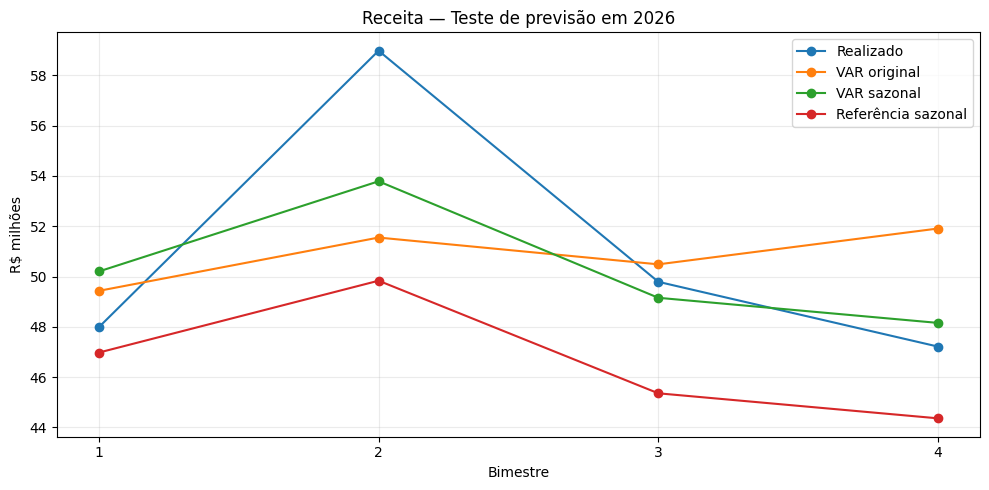

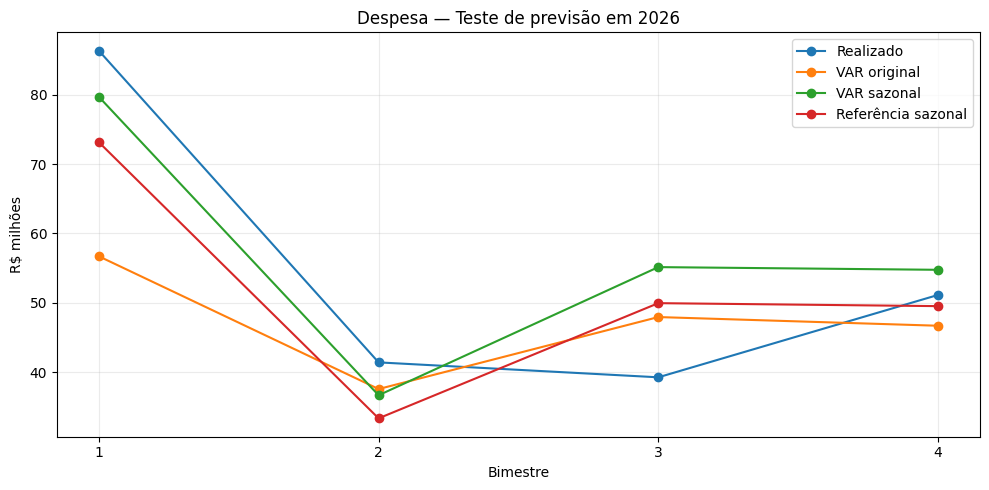


Arquivo gerado: CERQUILHO_VALIDACAO_VAR_2026.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

# ===========================================================
# VALIDAÇÃO DOS MODELOS VAR COM DADOS REAIS DE 2026
# Treinamento: 2017-B1 até 2025-B6
# Teste: 2026-B1 até 2026-B4
# ===========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Usa a base criada no código anterior.
# Colunas: Receita e Despesa, em R$ milhões.

dados = base[["Receita", "Despesa"]].copy()

assert len(dados) == 58, (
    "Esperávamos 58 observações até 2026-B4. "
    "Confira a base antes de continuar."
)

# Separação cronológica
treino = dados.iloc[:54].copy()
real_2026 = dados.iloc[54:58].copy()

# Os modelos não recebem nenhum valor de 2026
prev_original, lag_original = prever_var_original(
    treino, 4
)

prev_anual, lag_anual = prever_var_anual(
    treino, 4
)

prev_referencia = prever_referencia(
    treino, 4
)

# -----------------------------------------------------------
# ORGANIZAR PREVISÕES E VALORES REAIS
# -----------------------------------------------------------

comparacao = pd.DataFrame({
    "Bimestre": [1, 2, 3, 4],

    "Receita real": real_2026["Receita"].to_numpy(),
    "Despesa real": real_2026["Despesa"].to_numpy(),

    "Receita VAR original": prev_original[:, 0],
    "Despesa VAR original": prev_original[:, 1],

    "Receita VAR anual": prev_anual[:, 0],
    "Despesa VAR anual": prev_anual[:, 1],

    "Receita referência": prev_referencia[:, 0],
    "Despesa referência": prev_referencia[:, 1],
})

# -----------------------------------------------------------
# CALCULAR ERROS
# -----------------------------------------------------------

def calcular_erros(reais, previstos):

    reais = np.asarray(reais, dtype=float)
    previstos = np.asarray(previstos, dtype=float)

    mae = np.mean(np.abs(reais - previstos))

    denominador = np.abs(reais) + np.abs(previstos)
    valido = denominador > 0

    if valido.any():
        smape = np.mean(
            200 * np.abs(
                reais[valido] - previstos[valido]
            ) / denominador[valido]
        )
    else:
        smape = 0.0

    erro_total = (
        previstos.sum() - reais.sum()
    )

    return mae, smape, erro_total


resultados = []

for variavel in ["Receita", "Despesa"]:

    reais = comparacao[f"{variavel} real"].to_numpy()

    for modelo in [
        "VAR original",
        "VAR anual",
        "referência"
    ]:

        previstos = comparacao[
            f"{variavel} {modelo}"
        ].to_numpy()

        mae, smape, erro_total = calcular_erros(
            reais, previstos
        )

        resultados.append({
            "Variável": variavel,
            "Modelo": modelo,
            "MAE (R$ mi)": mae,
            "sMAPE (%)": smape,
            "Real até B4 (R$ mi)": reais.sum(),
            "Previsto até B4 (R$ mi)": previstos.sum(),
            "Erro acumulado (R$ mi)": erro_total
        })

avaliacao = pd.DataFrame(resultados)

print("\n" + "=" * 60)
print("COMPARAÇÃO: PREVISÕES X REALIZADO — 2026")
print("=" * 60)
print(comparacao.round(2).to_string(index=False))

print("\n" + "=" * 60)
print("DESEMPENHO DOS MODELOS EM 2026")
print("=" * 60)
print(avaliacao.round(2).to_string(index=False))

print("\nDefasagens selecionadas:")
print("VAR original:", lag_original)
print("VAR anual:", lag_anual)

# -----------------------------------------------------------
# RESULTADO ORÇAMENTÁRIO ATÉ AGOSTO
# -----------------------------------------------------------

resultado_real = (
    comparacao["Receita real"].sum()
    - comparacao["Despesa real"].sum()
)

resultados_fiscais = []

for modelo in ["VAR original", "VAR anual", "referência"]:

    resultado_previsto = (
        comparacao[f"Receita {modelo}"].sum()
        - comparacao[f"Despesa {modelo}"].sum()
    )

    resultados_fiscais.append({
        "Modelo": modelo,
        "Resultado real (R$ mi)": resultado_real,
        "Resultado previsto (R$ mi)": resultado_previsto,
        "Erro do resultado (R$ mi)": (
            resultado_previsto - resultado_real
        )
    })

fiscais = pd.DataFrame(resultados_fiscais)

print("\nRESULTADO ORÇAMENTÁRIO — JAN A AGO/2026")
print(fiscais.round(2).to_string(index=False))

# -----------------------------------------------------------
# GRÁFICOS PARA AVALIAR O COMPORTAMENTO BIMESTRAL
# -----------------------------------------------------------

for variavel in ["Receita", "Despesa"]:

    plt.figure(figsize=(10, 5))

    for coluna, nome in [
        (f"{variavel} real", "Realizado"),
        (f"{variavel} VAR original", "VAR original"),
        (f"{variavel} VAR anual", "VAR sazonal"),
        (f"{variavel} referência", "Referência sazonal")
    ]:

        plt.plot(
            comparacao["Bimestre"],
            comparacao[coluna],
            marker="o",
            label=nome
        )

    plt.title(f"{variavel} — Teste de previsão em 2026")
    plt.xlabel("Bimestre")
    plt.ylabel("R$ milhões")
    plt.xticks([1, 2, 3, 4])
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

# -----------------------------------------------------------
# SALVAR PLANILHA DE VALIDAÇÃO
# -----------------------------------------------------------

arquivo = "CERQUILHO_VALIDACAO_VAR_2026.xlsx"

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    comparacao.to_excel(
        writer, sheet_name="COMPARACAO_BIM", index=False
    )

    avaliacao.to_excel(
        writer, sheet_name="ERROS_MODELOS", index=False
    )

    fiscais.to_excel(
        writer, sheet_name="RESULTADOS_FISCAIS", index=False
    )

print("\nArquivo gerado:", arquivo)
files.download(arquivo)
